# Feature #4: Ask Spendif intent classifier

Goal: read a question like `how much did i spend from aug 4 to aug 11` and predict its **intent** (`spend_total`).
Dates and wallets are NOT the model's job: the date parser and the phone handle those.

Train on `datasets/intents.csv`, test on `datasets/intents_test.csv` (written separately, never used for training or tuning).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

train = pd.read_csv('../datasets/intents.csv')
test = pd.read_csv('../datasets/intents_test.csv')

# Same cleaning for train, test and the API: lowercase + trim
prep = lambda s: s.str.lower().str.strip()
X_train, y_train = prep(train['question']), train['intent']
X_test, y_test = prep(test['question']), test['intent']

print(train.shape, test.shape)
train['intent'].value_counts()

(410, 2) (114, 2)


intent
spend_total          61
finance_tip          61
out_of_scope         54
weekly_summary       50
list_transactions    49
income_total         48
daily_summary        45
report               42
Name: count, dtype: int64

## A. Baseline
Always guess the most common intent. Any real model has to beat this by a lot.

In [2]:
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print('baseline test accuracy:', round(accuracy_score(y_test, dummy.predict(X_test)), 3))

baseline test accuracy: 0.123


## B. Word n-grams vs char n-grams
- `word (1,2)`: single words and word pairs (`how much`, `weekly summary`).
- `char_wb (2,4)`: 2–4 letter chunks inside each word. `summry` still shares `sum`, `umm`... with `summary`, so typos hurt less.

Cross-validation on train is for choosing; the test score is only for reporting.

In [3]:
def make(analyzer, ngrams):
    return Pipeline([
        ('tfidf', TfidfVectorizer(analyzer=analyzer, ngram_range=ngrams, sublinear_tf=True)),
        ('clf', LogisticRegression(max_iter=2000, C=10)),
    ])

candidates = {
    'word (1,2)': make('word', (1, 2)),
    'char_wb (2,4)': make('char_wb', (2, 4)),
}

rows = []
for name, pipe in candidates.items():
    cv = cross_val_score(pipe, X_train, y_train, cv=5).mean()
    pipe.fit(X_train, y_train)
    rows.append({'model': name, 'cv_train': round(cv, 3),
                 'test': round(accuracy_score(y_test, pipe.predict(X_test)), 3)})
results = pd.DataFrame(rows)
results

,model,cv_train,test
0,"word (1,2)",0.773,0.833
1,"char_wb (2,4)",0.820,0.886


In [4]:
# Choose by cross-validation (not by test score)
best_name = results.sort_values('cv_train', ascending=False).iloc[0]['model']
model = candidates[best_name]
print('chosen:', best_name)

chosen: char_wb (2,4)


## C. Where does it go wrong?

In [5]:
pred = model.predict(X_test)
print(classification_report(y_test, pred, zero_division=0))

                   precision    recall  f1-score   support

    daily_summary       0.87      0.93      0.90        14
      finance_tip       0.93      0.93      0.93        14
     income_total       0.88      1.00      0.93        14
list_transactions       1.00      0.93      0.96        14
     out_of_scope       0.75      0.80      0.77        15
           report       1.00      0.93      0.96        14
      spend_total       0.77      0.67      0.71        15
   weekly_summary       0.93      0.93      0.93        14

         accuracy                           0.89       114
        macro avg       0.89      0.89      0.89       114
     weighted avg       0.89      0.89      0.89       114



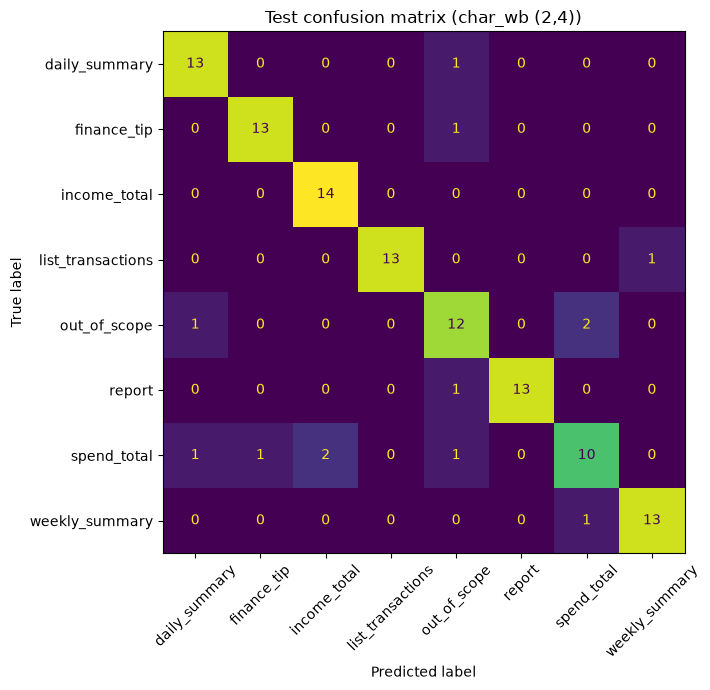

In [6]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, xticks_rotation=45, colorbar=False)
ax.set_title(f'Test confusion matrix ({best_name})')
plt.tight_layout()
plt.show()

In [7]:
# Read every mistake: this teaches more than the accuracy number
proba = model.predict_proba(X_test)
conf = proba.max(axis=1)
mistakes = test.assign(pred=pred, confidence=conf.round(2))[pred != y_test]
mistakes.sort_values('confidence', ascending=False)

,question,intent,pred,confidence
65,how much did lazada take from me this year,spend_total,income_total,0.73
62,What day is it today?,out_of_scope,daily_summary,0.70
1,What's the damage for February so far,spend_total,out_of_scope,0.59
36,what did i pay for 2 weeks ago,list_transactions,weekly_summary,0.43
30,how bad was my spending these past 7 days,weekly_summary,spend_total,0.43
49,How do I make my salary last until the next pa...,finance_tip,out_of_scope,0.40
112,pwede ba magbayad ng meralco bill dito?,out_of_scope,spend_total,0.40
7,How much money left my wallet over the past 2 ...,spend_total,income_total,0.32
19,quick look at feb 14 spending,daily_summary,out_of_scope,0.30
111,magkano palitan ng dollar to peso ngayon?,out_of_scope,spend_total,0.30


## D. Pick `THRESHOLD`
Below the threshold the API returns `intent: null` and the app asks the user to rephrase.
Trade-off: higher threshold = fewer wrong answers, but more "I didn't get that".

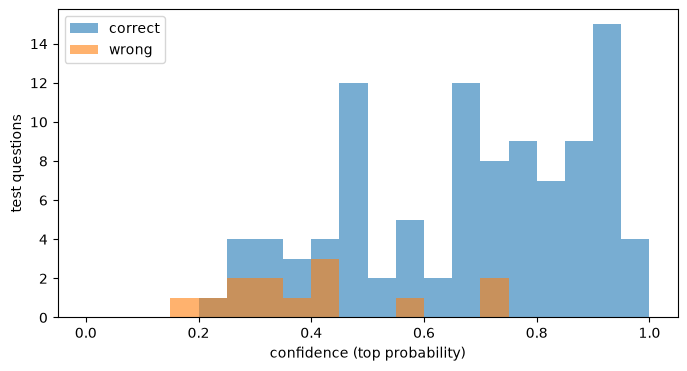

,threshold,answered,accuracy_when_answered,wrong_answers_shown
0,0.0,100%,0.886,13
1,0.2,99%,0.894,12
2,0.3,92%,0.914,9
3,0.4,83%,0.937,6
4,0.5,67%,0.961,3
5,0.6,60%,0.971,2
6,0.7,47%,0.963,2


In [8]:
correct = pred == y_test.values

plt.figure(figsize=(8, 4))
plt.hist(conf[correct], bins=20, range=(0, 1), alpha=0.6, label='correct')
plt.hist(conf[~correct], bins=20, range=(0, 1), alpha=0.6, label='wrong')
plt.xlabel('confidence (top probability)')
plt.ylabel('test questions')
plt.legend()
plt.show()

rows = []
for t in [0.0, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    answered = conf >= t
    rows.append({
        'threshold': t,
        'answered': f'{answered.mean():.0%}',
        'accuracy_when_answered': round(correct[answered].mean(), 3) if answered.any() else None,
        'wrong_answers_shown': int((answered & ~correct).sum()),
    })
pd.DataFrame(rows)

In [9]:
THRESHOLD = 0.35  # 0.4 refused 10 correct answers to avoid 1 wrong one
print('wrong answers shown:', int(((conf >= THRESHOLD) & ~correct).sum()),
      '| questions refused:', int((conf < THRESHOLD).sum()))

wrong answers shown: 7 | questions refused: 15


## E. Try it on new questions

In [10]:
def ask(q):
    p = model.predict_proba([q.lower().strip()])[0]
    i = int(np.argmax(p))
    intent = model.classes_[i] if p[i] >= THRESHOLD else None
    return {'question': q, 'intent': intent, 'confidence': round(float(p[i]), 2)}

pd.DataFrame([ask(q) for q in [
    'how much did i spend from aug 4 to aug 11',
    'weekly summary',
    'all transactions report 10 years ago',
    'magkano kinita ko last month',
    'summry for today',
    'what is an emergency fund',
    'banana',
    'how much is a jollibee chickenjoy',
]])

,question,intent,confidence
0,how much did i spend from aug 4 to aug 11,spend_total,0.86
1,weekly summary,weekly_summary,0.99
2,all transactions report 10 years ago,report,0.92
3,magkano kinita ko last month,income_total,0.89
4,summry for today,daily_summary,0.96
5,what is an emergency fund,finance_tip,0.92
6,banana,out_of_scope,0.84
7,how much is a jollibee chickenjoy,NaN,0.29


## F. If a pair keeps getting confused
Add more **training** rows for that pair and re-run. Never edit `intents_test.csv` to make the score go up,
or the test stops measuring anything.

## G. Save for the API
Refit on train only (test stays unseen), then save next to `categorizer.joblib`.

In [11]:
from pathlib import Path

model.fit(X_train, y_train)
out = Path('../service/model/intents.joblib')
joblib.dump(model, out)
print(out, f'{out.stat().st_size / 1024:.0f} KB')

# Self-check: the saved file predicts the same as the model in memory
loaded = joblib.load(out)
assert (loaded.predict(X_test) == model.predict(X_test)).all()

..\service\model\intents.joblib 247 KB


## Takeaways (answer in your own words)

1. Why does `char_wb` help (or not) with typos like `summry` and `reprot`?
   A word n-gram model treats “summry” as a word it has never seen, so it gets no features at all and the model is guessing from the rest of the sentence. char_wb splits each word into 2–4 letter pieces, so a misspelled word still keeps most of its pieces. “summry” still has “ su”, “sum”, “umm” and “mm” in common with “summary”, and “reprot” still has “ re”, “rep” and “ep” in common with “report”. That’s usually enough to land on the right intent. It only helps partly, though. The pieces right around the typo are lost (“mar”/”ary” in summary, “por”/”ort” in report). Short words and typos near the start of a word lose a bigger share of their pieces, and a word with several typos can drift toward some other intent. Unrelated words can also share pieces by accident. char_wb makes typos hurt less; it doesn’t fix them.
2. Why fix the training data instead of the test file?
   The test file stands in for real users, who will type whatever they like. If I edit it until the score goes up, the number shows how well I fit the test file, not how the model will do on new questions, so the test stops measuring anything. Adding training rows actually changes what the model learns, and an unedited test file tells me honestly whether that helped. I also shouldn’t use the test score to pick between models. That’s why the model is chosen by cross-validation on the training data.
3. What would the model do with "banana" if there were no `out_of_scope` class?
   It would still pick one of the 7 real intents. Logistic regression has to spread 100% of the probability across the classes it knows, and it has no way to say “none of these.” “banana” would go to whichever intent shares the most letter pieces with it, with low, spread-out confidence. The threshold might catch it, but not reliably. With 7 classes the top probability can never fall below about 14%, and one random overlap can push it past 0.35. The out_of_scope class gives the model a real place to put nonsense and off-topic questions. That matters for questions like “how much is a jollibee chickenjoy”, which looks a lot like spend_total but isn’t about the user’s own spending.
4. Which threshold did you pick, and what did you trade for it?
   I picked 0.35. On the 90 test questions it refuses 10 and answers 80, and 6 of those 80 answers are wrong, so it’s about 92.5% accurate on the questions it answers. Of the 9 total mistakes, it blocks 3. The cost is that 7 questions the model would have gotten right now get “I didn’t get that.” Raising it to 0.4 was a bad deal: it refused 10 more correct answers just to avoid 1 more wrong one. Annoying users with constant rephrase requests seemed worse than showing one extra wrong answer, which users can see is wrong and rephrase. If a wrong answer were costly (for example, showing a wrong spending total as if it were fact), I’d push the threshold higher.